# Imports

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pylab as plt
import seaborn as sns

# Fonte de dados para analise

- https://medium.com/@renata-biaggi/guia-completo-an%C3%A1lise-explorat%C3%B3ria-de-dados-com-python-2964fa2940f4

# EDA

## Entendendo a base de dados

In [9]:
def transformar_dataset_to_csv(path, path_save, nome):

    colunas = ["id", "date", "Temperature", "Humidity", "Light", "CO2", "HumidityRatio", "Occupancy"]
    colunas_sem_id = ["date", "Temperature", "Humidity", "Light", "CO2", "HumidityRatio", "Occupancy"]
    
    dataset = pd.read_csv(
        path,
        header = 0,
        names = colunas,
        usecols = colunas_sem_id,
        parse_dates = ["date"],
    )

    dataset.to_csv(path_save + f"/{nome}.csv", index=False)
    
    return dataset
    
datatest = transformar_dataset_to_csv("./dataset/occupancy_detection/dataset_txt/datatest.txt", "./dataset/occupancy_detection/dataset_csv", "datatest")
datatest2 = transformar_dataset_to_csv("./dataset/occupancy_detection/dataset_txt/datatest2.txt", "./dataset/occupancy_detection/dataset_csv", "datatest2")
datatraining = transformar_dataset_to_csv("./dataset/occupancy_detection/dataset_txt/datatraining.txt", "./dataset/occupancy_detection/dataset_csv", "datatraining")

In [53]:
dataset_completo = pd.concat([datatest, datatest2, datatraining])

In [51]:
dataset_completo.to_csv("./dataset/occupancy_detection/dataset_csv/dataset_completo.csv")

In [46]:
linha = "=" * 70

print(linha)
print(f"Resumo sem graficos do Dataset de Detecção de Ocupação")
print(linha)

linhas, colunas = dataset_completo.shape
print(f"\nDimensões: {linhas:,} linhas × {colunas} colunas")

print(f"\nColunas ({colunas}):")
for i, (col, dtype) in enumerate(zip(dataset_completo.columns, dataset_completo.dtypes), start=1):
    print(f"{i:>2}.{col:<20} → {dtype}")

print("A ultima linha é a linha que queremos prever")

print("\nValores nulos por coluna:")
nulos = dataset_completo.isnull().sum()
for col, qtd in nulos.items():
    pct = 100 * qtd / len(dataset_completo)
    marca = "✅" if qtd == 0 else "⚠️"
    print(f"   {marca} {col:<20} {qtd:>6} ({pct:5.2f}%)")

print("\nPrimeiras 5 linhas:")
print(dataset_completo.head().to_string())

print("\nEstatísticas descritivas:")
print(dataset_completo.describe().round(3).to_string())

print("\nDados Duplicados:")
print(dataset_completo.duplicated().sum())

print("\nDistribuição das Classes:")
dataset_classes = dataset_completo['Occupancy']

contagem   = dataset_classes.value_counts().sort_index()
percentual = dataset_classes.value_counts(normalize=True).sort_index() * 100

print(f"\n{'Classe':<14}{'Qtd':>12}{'%':>10}")

for classe in contagem.index:
    print(f"{classe:<14}{contagem[classe]:>12}{percentual[classe]:>9.2f}%")

print("\n" + linha)

Resumo sem graficos do Dataset de Detecção de Ocupação

Dimensões: 20,560 linhas × 7 colunas

Colunas (7):
 1.date                 → datetime64[us]
 2.Temperature          → float64
 3.Humidity             → float64
 4.Light                → float64
 5.CO2                  → float64
 6.HumidityRatio        → float64
 7.Occupancy            → int64
A ultima linha é a linha que queremos prever

Valores nulos por coluna:
   ✅ date                      0 ( 0.00%)
   ✅ Temperature               0 ( 0.00%)
   ✅ Humidity                  0 ( 0.00%)
   ✅ Light                     0 ( 0.00%)
   ✅ CO2                       0 ( 0.00%)
   ✅ HumidityRatio             0 ( 0.00%)
   ✅ Occupancy                 0 ( 0.00%)

Primeiras 5 linhas:
                 date  Temperature  Humidity       Light         CO2  HumidityRatio  Occupancy
0 2015-02-02 14:19:00      23.7000    26.272  585.200000  749.200000       0.004764          1
1 2015-02-02 14:19:59      23.7180    26.290  578.400000  760.400000     

# Analise das features numericas do dataset em grafico

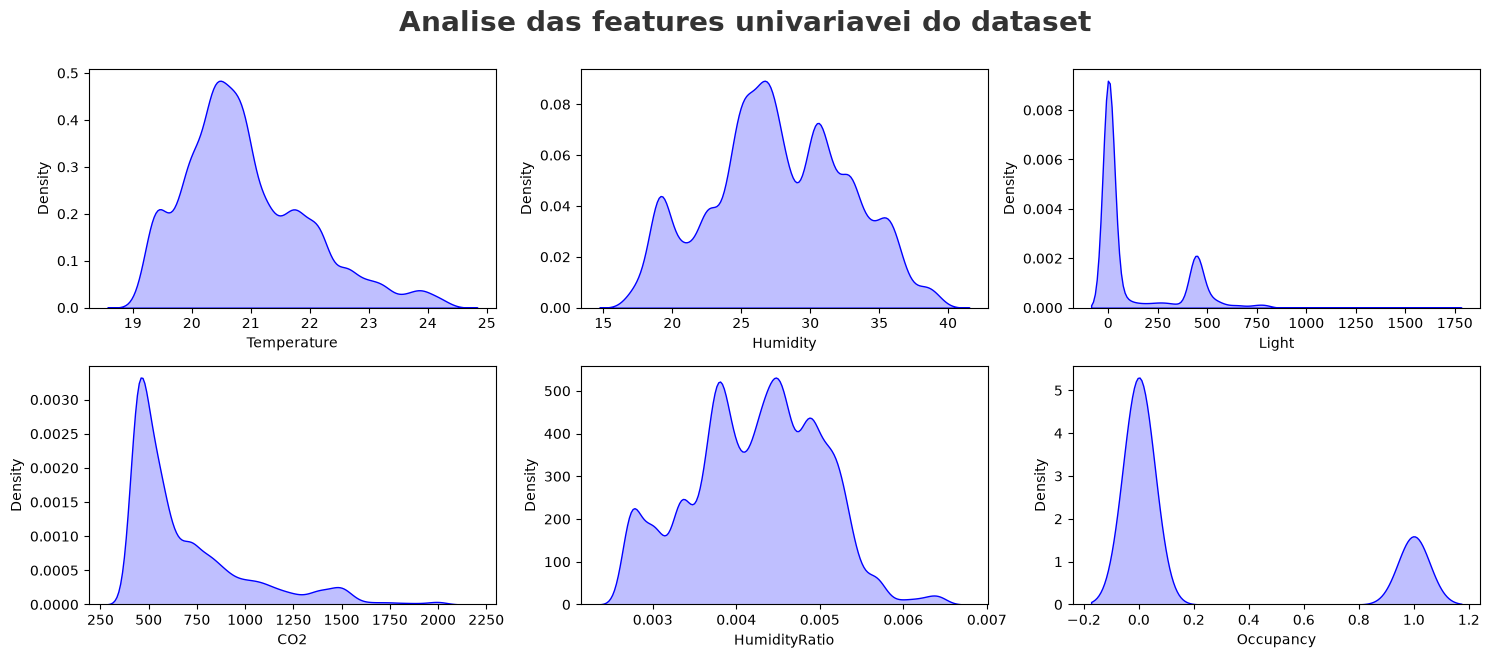

In [27]:
features_numericas = ["Temperature", "Humidity", "Light", "CO2", "HumidityRatio", "Occupancy"]

plt.figure(figsize=(15,15))
plt.suptitle("Analise das features univariavei do dataset", fontsize=20, fontweight='bold', alpha=0.8, y = 1.)

for i in range(len(features_numericas)):
    plt.subplot(5,3, i + 1)
    
    sns.kdeplot(x = dataset_completo[features_numericas[i]], fill=True, color = 'b')
    plt.xlabel(features_numericas[i])
    plt.tight_layout()

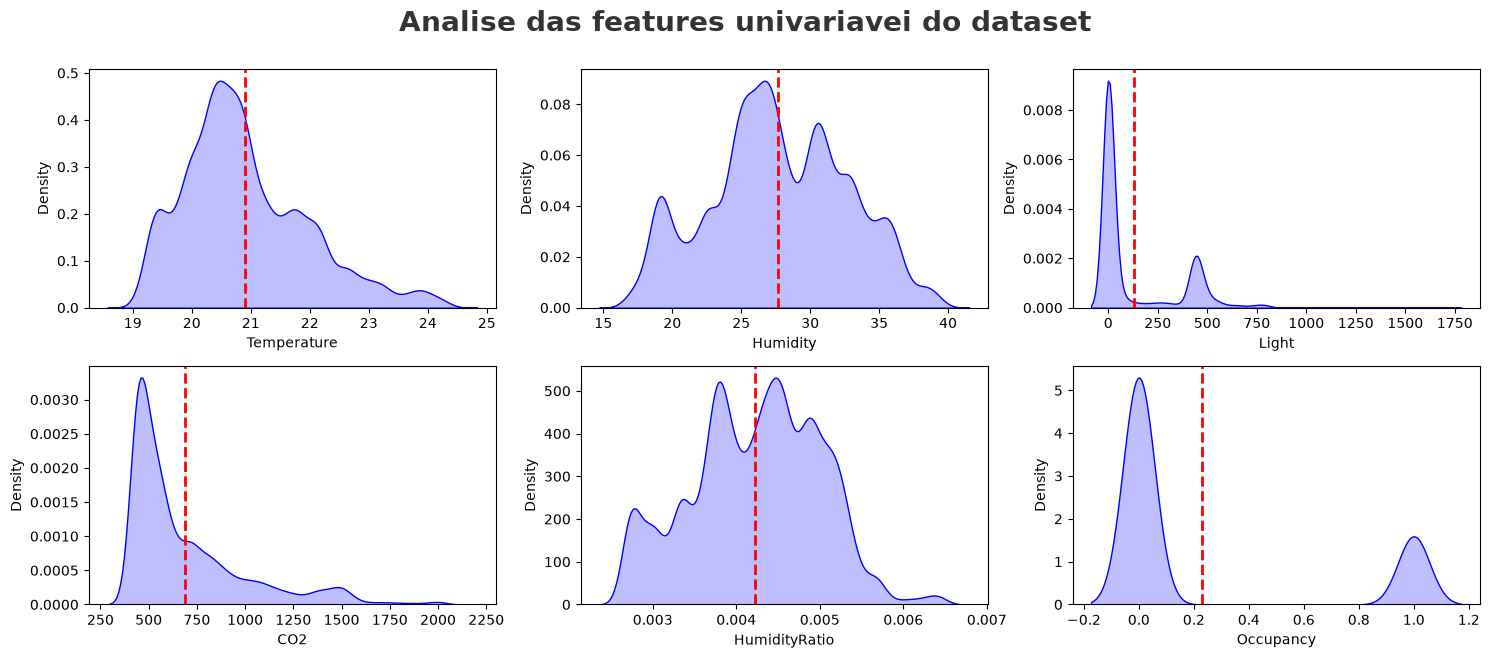

In [28]:
features_numericas = ["Temperature", "Humidity", "Light", "CO2", "HumidityRatio", "Occupancy"]

plt.figure(figsize=(15,15))
plt.suptitle("Analise das features univariavei do dataset", fontsize=20, fontweight='bold', alpha=0.8, y = 1.)

for i in range(len(features_numericas)):
    plt.subplot(5,3, i + 1)
    
    media = dataset_completo[features_numericas[i]].mean()
    plt.axvline(media, color="red", linestyle="--", linewidth=2, label=f"Média = {media:.2f}")
    
    sns.kdeplot(x = dataset_completo[features_numericas[i]], fill=True, color = 'b')
    plt.xlabel(features_numericas[i])
    plt.tight_layout()

# Matriz Correlação Variáveis

In [29]:
matriz = dataset_completo.corr()

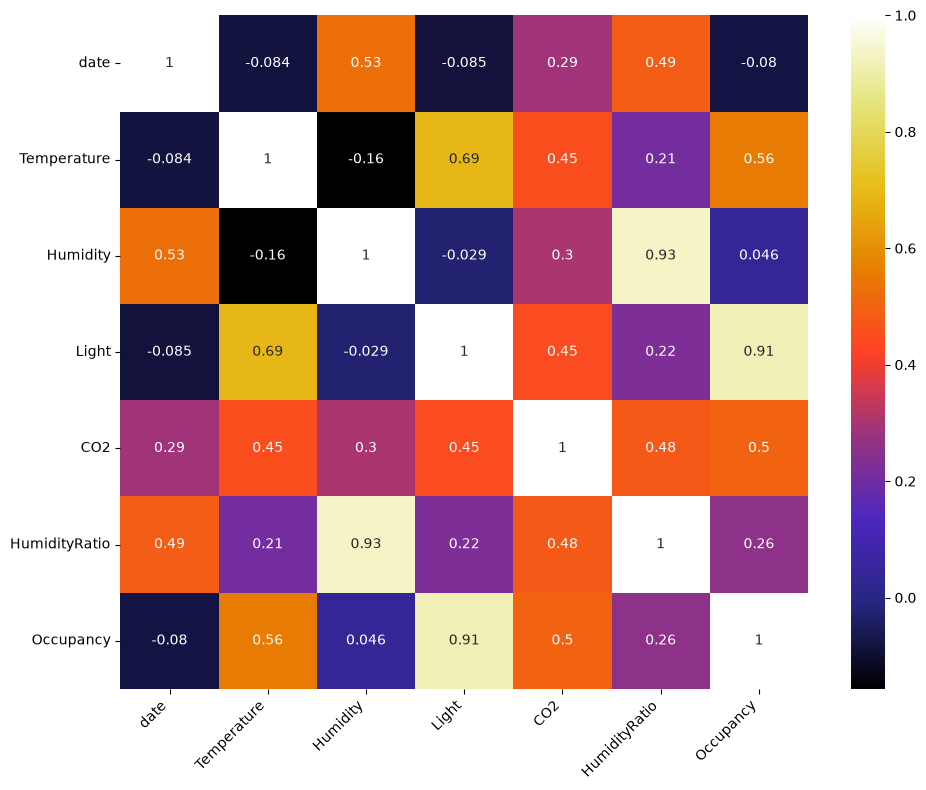

In [49]:
plt.figure(figsize= (10, 8))
sns.heatmap(matriz, cmap='CMRmap', annot=True)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()   
plt.show()